In [1]:
# from google.colab import drive
# drive.mount('/content/drive')

In [2]:
!pip install SimPEG

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 513.9/513.9 kB 13.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 64.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.7/211.7 kB 23.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 172.5/172.5 kB 21.5 MB/s eta 0:00:00
  Created wheel for SimPEG: filename=simpeg-0.25.2-py3-none-any.whl size=595276 sha256=9c7a3dfcfe8039b7fd879745ea871163879d32b720caafc93b98e05cffeaaeb8
  Stored in directory: /root/.cache/pip/wheels/8a/db/6f/b6da5be3c64674bd3af27db599ff3f633a39e325b67485a2f1
  Created wheel for pymatsolver: filename=pymatsolver-0.4.0-py3-none-any.whl size=15857 sha256=5718fdbef8405b40ad48dbd3c95b6519786dd49d82e4f7a2075f9ff2

In [3]:
import scipy as sp
import numpy as np
import matplotlib.pyplot as plt
from simpeg import (
    data,
    data_misfit,
    directives,
    maps,
    inverse_problem,
    optimization,
    inversion,
    regularization,
)

from scipy.spatial import cKDTree

from simpeg.potential_fields import magnetics
from simpeg import utils
from simpeg.utils import mkvc
from discretize.utils import mesh_builder_xyz, refine_tree_xyz, active_from_xyz
from discretize import TensorMesh


In [4]:
import numpy as np
import h5py  # to read data from .mat
import matplotlib.pyplot as plt
import keras
import tensorflow as tf
#import keras.backend as K
import pandas as pd
import os
from scipy.stats import norm
import matplotlib

In [5]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np

In [6]:
nc = np.arange(25,2625,25) # row points
nr = np.arange(25,825,25)*-1 # column points

In [7]:
meshgrid = np.meshgrid(nc,nr)
mesh_pts = np.c_[meshgrid[0].reshape(-1,1),meshgrid[1].reshape(-1,1)]

In [8]:
mesh_pts.shape

(3328, 2)

In [9]:
# Create and array of observation points
xr = np.arange(0, 2600, 25)
zr = np.ones_like(xr)*10
yr = np.zeros_like(xr)
rxLoc = np.c_[mkvc(xr), mkvc(yr), mkvc(zr)]

In [10]:
rxLoc.shape

(104, 3)

In [11]:
x_topo = np.arange(0, 2601, 25)
y_topo = np.arange(-5000,5001,25)

In [12]:
grid = np.meshgrid(x_topo,y_topo)

In [13]:
topo_grid = np.c_[grid[0].ravel(),grid[1].ravel(),np.zeros_like(grid[0].ravel())]

In [14]:
# Assume an inducing field
h0_amplitude, h0_inclination, h0_declination = (46077, 58.0, 2.0)

# The magnetization is set along a different direction (induced + remanence)
M_b = np.array([45.0, 270.0])
M_d = np.array([-60.0, 30.0]) #Assume everything is induced

# # Block with an effective susceptibility
chi_e_b = 0.1
chi_e_d = 0.05
chi_e_a = 0.1

In [15]:
# Creating a SimPEG mesh with similar extent as the GemPy model

mesh = TensorMesh(
    [
        [(25, 104)],
        [(10000, 1)],
        [(25, 32)]
    ]
)
mesh.x0 = [0, -5000, -800]
mesh

TensorMesh: 3,328 cells

                      MESH EXTENT             CELL WIDTH      FACTOR
  dir    nC        min           max         min       max      max
  ---   ---  ---------------------------  ------------------  ------
   x    104          0.00      2,600.00     25.00     25.00    1.00
   y      1     -5,000.00      5,000.00 10,000.00 10,000.00    1.00
   z     32       -800.00          0.00     25.00     25.00    1.00

In [16]:
# Define the active cells from topo
actv = active_from_xyz(mesh, topo_grid)
nC = int(actv.sum())
# Create reduced identity map
idenMap = maps.IdentityMap(nP=nC)

In [17]:
print("idenMap:", idenMap)
print("idenMap.nP =", idenMap.nP if hasattr(idenMap, 'nP') else "None")

idenMap: IdentityMap(3328,3328)
idenMap.nP = 3328


In [18]:
nC

3328

In [19]:
xyz = mesh.cell_centers[actv]   # (2048, 3)
chi = np.zeros(nC)

# BLOCK
block_xmin, block_xmax = 320, 600
block_zmin, block_zmax = -400, -100

ind_block = (
    (xyz[:,0] >= block_xmin) & (xyz[:,0] <= block_xmax) &
    (xyz[:,2] >= block_zmin) & (xyz[:,2] <= block_zmax)
)

chi[ind_block] = chi_e_b

# DIKE
dike_top_x = 1000
dike_width = 150
dike_height = 50
n_layers = 9
shift_per_layer = 40

ind_dike_total = np.zeros(nC, dtype=bool)

depth_offset = -100

for i in range(n_layers):

    layer_z_top = depth_offset - i * dike_height
    layer_z_bottom = depth_offset - (i+1) * dike_height
    layer_x_center = dike_top_x + i * shift_per_layer

    xmin = layer_x_center - dike_width/2
    xmax = layer_x_center + dike_width/2

    ind_layer = (
        (xyz[:,0] >= xmin) & (xyz[:,0] <= xmax) &
        (xyz[:,2] <= layer_z_top) & (xyz[:,2] >= layer_z_bottom)
    )

    ind_dike_total |= ind_layer
    chi[ind_layer] = chi_e_d   # scalar susceptibility

# TRIANGLE (new feature)
tri_xmin, tri_xmax = 2000, 2500
tri_zmin, tri_zmax = -400, -100

# Calculate the upper Z-boundary of the triangle based on X position
# Left side line: (2000, -400) to (2250, -100) -> z = 1.2*(x - 2000) - 400
# Right side line: (2250, -100) to (2500, -400) -> z = -1.2*(x - 2250) - 100
z_tri_upper_boundary = np.where(
    xyz[:,0] <= (tri_xmin + tri_xmax) / 2, # if x is on the left half of the triangle
    1.2 * (xyz[:,0] - tri_xmin) + tri_zmin, # equation for the left slope
    -1.2 * (xyz[:,0] - tri_xmax) + tri_zmin  # equation for the right slope
)

ind_triangle = (
    (xyz[:,0] >= tri_xmin) & (xyz[:,0] <= tri_xmax) &
    (xyz[:,2] >= tri_zmin) & (xyz[:,2] <= z_tri_upper_boundary) # points must be below or on the upper boundary line
)

chi[ind_triangle] = chi_e_a


M = np.zeros((nC, 2))

# block orientation
M[ind_block, 0] = M_b[0]
M[ind_block, 1] = M_b[1]

# dike orientation
M[ind_dike_total, 0] = M_d[0]
M[ind_dike_total, 1] = M_d[1]

# Note: Magnetization for the triangle is not specified, so it remains [0,0].

In [20]:
M.shape

(3328, 2)

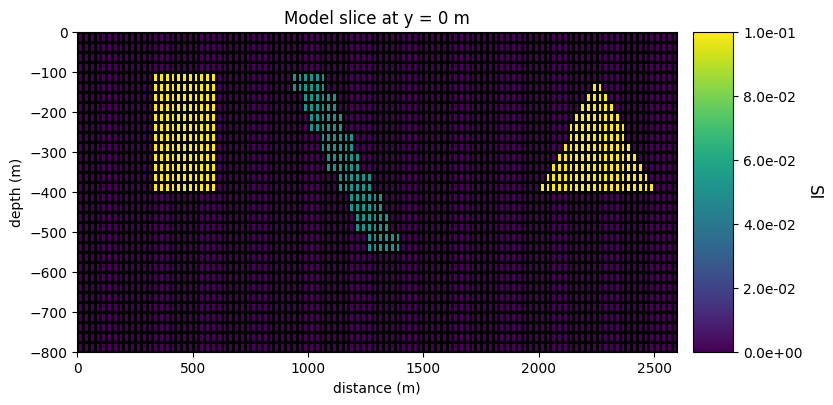

In [21]:
plotting_model = chi

plotting_map = maps.InjectActiveCells(mesh, actv, np.nan)

fig = plt.figure(figsize=(8, 4))

ax1 = fig.add_axes([0.08, 0.1, 0.75, 0.8])

mesh.plot_slice(
    plotting_map * plotting_model,
    normal="Y",
    ax=ax1,
    ind=int(mesh.shape_cells[1] / 2),  # y = 0 mid-plane
    grid=True,
    clim=(np.nanmin(plotting_model), np.nanmax(plotting_model)),
    pcolor_opts={"cmap": "viridis"},
)

ax1.set_title("Model slice at y = 0 m")
ax1.set_xlabel("distance (m)")
ax1.set_ylabel("depth (m)")

ax2 = fig.add_axes([0.85, 0.1, 0.05, 0.8])
norm = matplotlib.colors.Normalize(
    vmin=np.nanmin(plotting_model),
    vmax=np.nanmax(plotting_model)
)
cbar = matplotlib.colorbar.ColorbarBase(
    ax2, norm=norm, orientation="vertical",
    cmap=matplotlib.cm.viridis, format="%.1e"
)
cbar.set_label("SI", rotation=270, labelpad=15, size=12)

plt.show()

In [22]:
receiver_list = magnetics.receivers.Point(rxLoc, components=["bx", "by", "bz"])
srcField = magnetics.sources.UniformBackgroundField(
    receiver_list=[receiver_list],
    amplitude=h0_amplitude,
    inclination=h0_inclination,
    declination=h0_declination,
)
surveyComp = magnetics.survey.Survey(srcField)

simulation = magnetics.simulation.Simulation3DIntegral(
    mesh=mesh,
    survey=surveyComp,
    chiMap=idenMap,
    active_cells=actv,
    is_amplitude_data=False, # set False to get bx, by, bz
)

In [23]:
model = chi

In [24]:
d_pred_tmp = simulation.dpred(model)

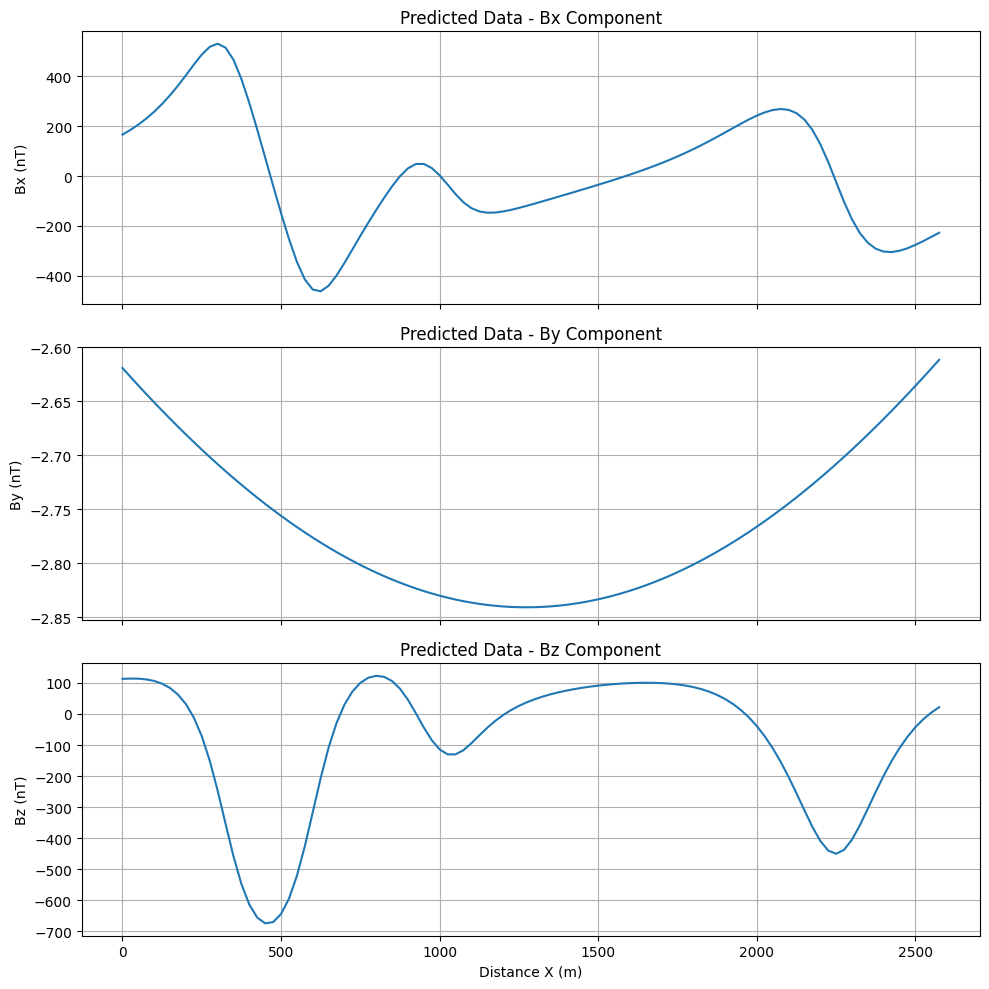

In [25]:
n_rx = len(rxLoc)

# SimPEG outputs multi-component data interleaved: [bx1, by1, bz1, bx2, by2, bz2, ...]
# Use step slicing to correctly extract each component
bx = d_pred_tmp[0::3]
by = d_pred_tmp[1::3]
bz = d_pred_tmp[2::3]

fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True)

axes[0].plot(rxLoc[:, 0], bx)
axes[0].set_title('Predicted Data - Bx Component')
axes[0].set_ylabel('Bx (nT)')
axes[0].grid(True)

axes[1].plot(rxLoc[:, 0], by)
axes[1].set_title('Predicted Data - By Component')
axes[1].set_ylabel('By (nT)')
axes[1].grid(True)

axes[2].plot(rxLoc[:, 0], bz)
axes[2].set_title('Predicted Data - Bz Component')
axes[2].set_xlabel('Distance X (m)')
axes[2].set_ylabel('Bz (nT)')
axes[2].grid(True)

plt.tight_layout()
plt.show()

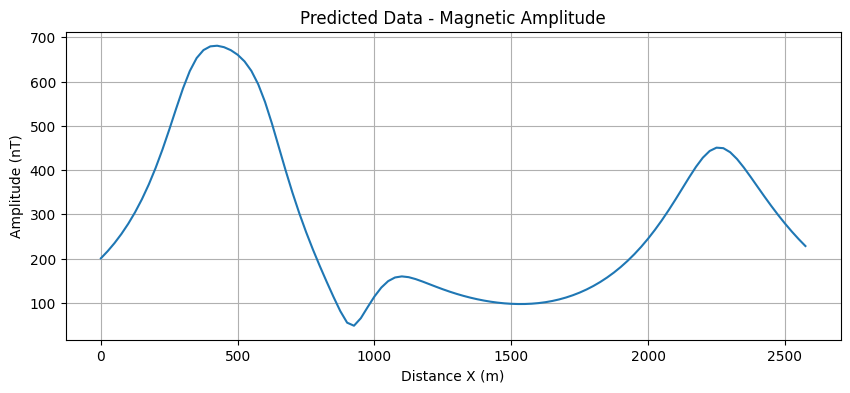

In [26]:
n_rx = len(rxLoc)

# Correctly slice the interleaved components
bx = d_pred_tmp[0::3]
by = d_pred_tmp[1::3]
bz = d_pred_tmp[2::3]

# Calculate amplitude from the 3 components
d_pred_amp = np.sqrt(bx**2 + by**2 + bz**2)

# Plot the clean amplitude
plt.figure(figsize=(10, 4))
plt.plot(rxLoc[:, 0], d_pred_amp)
plt.title('Predicted Data - Magnetic Amplitude')
plt.xlabel('Distance X (m)')
plt.ylabel('Amplitude (nT)')
plt.grid(True)
plt.show()

# Add noise to the amplitude to create observed data
d_sim = d_pred_amp + np.random.randn(len(rxLoc)) * 20

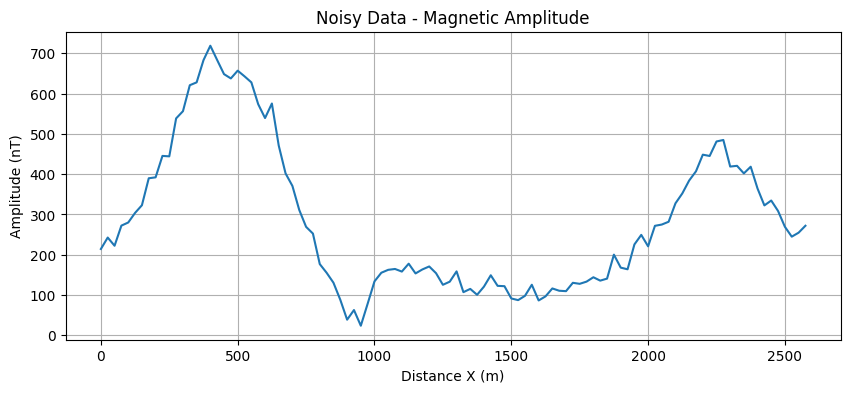

In [27]:
plt.figure(figsize=(10, 4))
plt.plot(rxLoc[:, 0], d_sim)
plt.title('Noisy Data - Magnetic Amplitude')
plt.xlabel('Distance X (m)')
plt.ylabel('Amplitude (nT)')
plt.grid(True)
plt.show()

In [28]:
data_covariance_matrix_inv = np.diag(np.square(1/20)*np.ones(len(rxLoc))) # Wd.T*Wd

In [29]:
len(rxLoc)

104

In [30]:
class AmplitudeSimulationWrapper:
    """
    A wrapper class to encapsulate the 312-to-104 component conversion.
    """
    def __init__(self, sim):
        self.sim = sim
        self.bx = None
        self.by = None
        self.bz = None
        self.amp = None

    def fields(self, m):
        # 1. Forward response -> 312 elements
        d_pred_3comp = self.sim.fields(m)
        # 2. Extract components and manually synthesize amplitude
        self.bx = d_pred_3comp[0::3]
        self.by = d_pred_3comp[1::3]
        self.bz = d_pred_3comp[2::3]
        self.amp = np.sqrt(self.bx**2 + self.by**2 + self.bz**2)
        return self.amp  # Returns 104 elements

    def Jtvec(self, m, v):
        # v is the 104-element amplitude residual
        # 3. Apply chain rule to distribute 104-element residual to 312 components
        amp_safe = np.where(self.amp == 0, 1e-8, self.amp)
        v_3comp = np.zeros(3*len(rxLoc))
        v_3comp[0::3] = v * (self.bx / amp_safe)
        v_3comp[1::3] = v * (self.by / amp_safe)
        v_3comp[2::3] = v * (self.bz / amp_safe)
        return self.sim.Jtvec(m, v_3comp)  # Calls underlying sim with 312 elements

# Instantiate the wrapper globally
sim_wrapper = AmplitudeSimulationWrapper(simulation)

# Decoder output is normalized to [0, 1]. Convert it to physical susceptibility before SimPEG.
susceptibility_scale = 0.1

def cal_Jtvec_unsupervised(m_pred_norm, d_obs):
    """
    m_pred_norm: decoder output in [0, 1], shape (mesh.nC,)
    d_obs: observed magnetic amplitude data, shape (104,)
    """
    m_real = susceptibility_scale * m_pred_norm

    # Forward response and residual in physical susceptibility units
    d_res = sim_wrapper.fields(m_real) - d_obs

    # Weighted residual: Wd.T @ Wd @ residual = Cd^{-1} residual
    d_res_normalize = np.matmul(data_covariance_matrix_inv, d_res)

    # Data-gradient wrt real susceptibility
    Jtdres_real = sim_wrapper.Jtvec(m_real, d_res_normalize)

    # Chain rule for m_real = susceptibility_scale * m_pred_norm
    Jtdres_norm = susceptibility_scale * Jtdres_real

    # True data misfit, only for logging
    data_misfit = np.matmul(d_res.T, d_res_normalize)

    return Jtdres_norm, data_misfit


def concatenate_Jtvec_unsupervised(decoder_output_model, d_obs):
    """
    decoder_output_model: normalized model, shape (batch_size, mesh.nC)
    d_obs: observed data, shape (n_data,)
    """
    batch_size = decoder_output_model.shape[0]

    Jtdres_batch = np.zeros((batch_size, mesh.nC))
    datamisfit_batch = np.zeros(batch_size)

    for i in range(batch_size):
        Jtdres_i, data_misfit_i = cal_Jtvec_unsupervised(
            decoder_output_model[i],
            d_obs
        )

        Jtdres_batch[i, :] = Jtdres_i
        datamisfit_batch[i] = data_misfit_i

    return Jtdres_batch, datamisfit_batch


In [31]:
def build_first_derivative_Wm(nx, nz):
    """
    Build first-order smoothness matrix Wm.
    Flatten order: x fastest, then z.
    Model index: idx = iz * nx + ix
    """

    rows = []

    # x-direction differences
    for iz in range(nz):
        for ix in range(nx - 1):
            row = np.zeros(nx * nz)
            idx1 = iz * nx + ix
            idx2 = iz * nx + ix + 1
            row[idx2] = 1.0
            row[idx1] = -1.0
            rows.append(row)

    # z-direction differences
    for iz in range(nz - 1):
        for ix in range(nx):
            row = np.zeros(nx * nz)
            idx1 = iz * nx + ix
            idx2 = (iz + 1) * nx + ix
            row[idx2] = 1.0
            row[idx1] = -1.0
            rows.append(row)

    Wm = np.vstack(rows).astype(np.float32)
    return Wm

# Define the output image dimensions
img_height = 32
img_width = 104

nx = img_width     # 104
nz = img_height    # 32

Wm_smooth = build_first_derivative_Wm(nx, nz)
Wm_smooth_tensor = tf.convert_to_tensor(Wm_smooth, dtype=tf.float32)

print("Wm_smooth shape:", Wm_smooth.shape)

Wm_smooth shape: (6520, 3328)


In [32]:
# Define the latent dimension (size of the input noise vector)
latent_dim = 50
# Define the data dimension (size of the observed data vector)
data_dim = len(rxLoc)

# Define the output image dimensions
img_height = 32
img_width = 104
img_channels = 1

def build_decoder(latent_dim, data_dim):
    # Dual Inputs
    decoder_input_coding = keras.layers.Input(shape=(latent_dim,), name="input_z")
    decoder_input_data = keras.layers.Input(shape=(data_dim,), name="input_data")

    # Concatenate the inputs
    x = keras.layers.Concatenate()([decoder_input_coding, decoder_input_data])

    # Add an additional Dense layer as requested previously
    x = layers.Dense(512)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    # Project the noise to a suitable shape for initial Conv2DTranspose
    # Target output (32, 104). Three Conv2DTranspose layers with strides=(2,2) means 8x upsampling.   # Maybe conv2dtranspose to reduce the model parameters
    # Initial feature map size should be (32/8, 104/8) = (4, 13)
    x = layers.Dense(4 * 13 * 256, use_bias=True)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Reshape((4, 13, 256))(x)

    # First Conv2DTranspose layer (upsamples from 4x13 to 8x26)
    x = layers.Conv2DTranspose(128, (5, 5), strides=(2, 2), padding='same', use_bias=True)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    # NEW: Additional Conv2DTranspose layer with strides=(1,1) to increase depth
    x = layers.Conv2DTranspose(128, (3, 3), strides=(1, 1), padding='same', use_bias=True)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    # Second Conv2DTranspose layer (upsamples from 8x26 to 16x52)
    x = layers.Conv2DTranspose(64, (5, 5), strides=(2, 2), padding='same', use_bias=True)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    # NEW: Additional Conv2DTranspose layer with strides=(1,1) to increase depth
    x = layers.Conv2DTranspose(64, (3, 3), strides=(1, 1), padding='same', use_bias=True)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    # Third Conv2DTranspose layer (upsamples from 16x52 to 32x104, final output size)
    # Sigmoid for pixel values between 0-1
    x = layers.Conv2DTranspose(img_channels, (5, 5), strides=(2, 2), padding='same', activation='sigmoid')(x) # Try other acti func like Relu

    # Flatten directly: The shape is (Batch, Height=32, Width=104, 1).
    # Standard Flatten iterates Width (X) fastest, then Height (Z).
    # This matches SimPEG's mesh order (X varies, then Z varies).
    outputs = layers.Flatten()(x) # Maybe flatten it elsewhere

    # Define the model with two inputs and one output
    model = keras.Model(inputs=[decoder_input_coding, decoder_input_data], outputs=outputs, name="decoder")
    return model

# Build the decoder model
decoder = build_decoder(latent_dim, data_dim)
decoder.summary()

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_z             │ (None, 50)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_data          │ (None, 104)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 154)       │          0 │ input_z[0][0],    │
│ (Concatenate)       │                   │            │ input_data[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 512)       │     79,360 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 512)       │      2,048 │ dense[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 512)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 13312)     │  6,829,056 │ re_lu[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 13312)     │     53,248 │ dense_1[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 13312)     │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 4, 13,     │          0 │ re_lu_1[0][0]     │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 8, 26,     │    819,328 │ reshape[0][0]     │
│ (Conv2DTranspose)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 8, 26,     │        512 │ conv2d_transpose… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 8, 26,     │          0 │ batch_normalizat… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_1  │ (None, 8, 26,     │    147,584 │ re_lu_2[0][0]     │
│ (Conv2DTranspose)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 8, 26,     │        512 │ conv2d_transpose… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 8, 26,     │          0 │ batch_normalizat… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_2  │ (None, 16, 52,    │    204,864 │ re_lu_3[0][0]     │
│ (Conv2DTranspose)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 52,    │        256 │ conv2d_transpose… │
│ (BatchNormalizatio… │ 64)               │            │                 

 Total params: 8,175,553 (31.19 MB)

 Trainable params: 8,147,137 (31.08 MB)

 Non-trainable params: 28,416 (111.00 KB)

In [33]:
tf.random.set_seed(42)
number_gaussian_realization = 5000
coding_size = latent_dim

codings = tf.random.normal(shape=[number_gaussian_realization,coding_size]) # generate 500 realizations of Gaussian noise.

# Reshape d_sim to (1, data_dim) and cast to float32 before tiling
d_input = tf.cast(tf.reshape(d_sim, [1, data_dim]), dtype=tf.float32)
data_multiple = tf.tile(d_input, tf.constant([number_gaussian_realization,1])) # replicate gravity data 500 times

predicted_model = decoder([codings,data_multiple])

In [34]:
n_epochs = 2000

latent_dim = 50
total_training_samples = 5000 # Using 5000 samples for the entire training set

alpha_d = 2.0
# Keep the same normalized-model smoothness regularization as v8.
beta = 5

optimizer = keras.optimizers.Adam(learning_rate=0.001)

surrogate_loss_record = []
true_total_loss_record = []
true_weighted_total_loss_record = []
data_loss_record = []
model_reg_record = []
surrogate_data_loss_record = []

print("Starting unsupervised training: data misfit + normalized smoothness regularization (non-batched)")
print("susceptibility_scale = {}, alpha_d = {}, beta = {}".format(susceptibility_scale, alpha_d, beta))

for epoch in range(1, n_epochs + 1):
    print("Epoch {}/{}".format(epoch, n_epochs))

    # 1. Random latent vectors for all samples
    codings = tf.random.normal(shape=[total_training_samples, latent_dim])

    # 2. Same observed data d_obs for all samples
    X_data = np.tile(d_sim, (total_training_samples, 1)).astype(np.float32)
    X_data_tensor = tf.convert_to_tensor(X_data, dtype=tf.float32)

    with tf.GradientTape() as tape:
        # 3. Decoder: z + d_obs -> normalized m_i in [0, 1]
        decoder_output_model = decoder([codings, X_data_tensor], training=True)

        # 4. External SimPEG data gradient wrt normalized model output
        t_data_np, datamisfit_all = concatenate_Jtvec_unsupervised(decoder_output_model.numpy(), d_sim)
        t_data_tensor = tf.stop_gradient(tf.convert_to_tensor(t_data_np, dtype=tf.float32))

        # 5. Surrogate data loss. Its gradient wrt decoder parameters injects the SimPEG data gradient.
        data_loss_surrogate = tf.reduce_sum(decoder_output_model * t_data_tensor) / total_training_samples

        # 6. Smoothness regularization on normalized decoder output, same as v8
        Wm_m = tf.linalg.matmul(decoder_output_model, Wm_smooth_tensor, transpose_b=True)
        model_reg_loss = beta * tf.reduce_sum(tf.square(Wm_m)) / total_training_samples

        # 7. Total surrogate loss
        loss = alpha_d * data_loss_surrogate + model_reg_loss

    # 8. Backprop
    gradients = tape.gradient(loss, decoder.trainable_variables)
    optimizer.apply_gradients(zip(gradients, decoder.trainable_variables))

    # 9. Logging & Physical Loss Calculation
    true_data_loss = np.mean(datamisfit_all)
    model_reg_val = model_reg_loss.numpy().item()
    surr_data_val = data_loss_surrogate.numpy().item()
    surr_total_val = loss.numpy().item()

    # Actual physical/logged loss and weighted version
    true_total_loss = true_data_loss + model_reg_val
    weighted_true_total_loss = alpha_d * true_data_loss + model_reg_val

    data_loss_record.append(true_data_loss)
    model_reg_record.append(model_reg_val)
    true_total_loss_record.append(true_total_loss)
    true_weighted_total_loss_record.append(weighted_true_total_loss)
    surrogate_data_loss_record.append(surr_data_val)
    surrogate_loss_record.append(surr_total_val)

    print(
        "  Epoch {}: true_misfit = {:.4e}, model_reg = {:.4e}, true_total_loss = {:.4e}, weighted_true_total_loss = {:.4e}, surrogate_loss = {:.4e}".format(
            epoch, true_data_loss, model_reg_val, true_total_loss, weighted_true_total_loss, surr_total_val
        )
    )


Starting unsupervised training: data misfit + normalized smoothness regularization (non-batched)
susceptibility_scale = 0.1, alpha_d = 2.0, beta = 5
Epoch 1/2000
  Epoch 1: true_misfit = 2.4846e+04, model_reg = 7.2303e+02, true_total_loss = 2.5569e+04, weighted_true_total_loss = 5.0414e+04, surrogate_loss = 6.9136e+04
Epoch 2/2000
  Epoch 2: true_misfit = 1.9246e+04, model_reg = 7.9144e+02, true_total_loss = 2.0037e+04, weighted_true_total_loss = 3.9283e+04, surrogate_loss = 5.2506e+04
Epoch 3/2000
  Epoch 3: true_misfit = 1.4158e+04, model_reg = 6.7177e+02, true_total_loss = 1.4830e+04, weighted_true_total_loss = 2.8988e+04, surrogate_loss = 3.4751e+04
Epoch 4/2000
  Epoch 4: true_misfit = 9.3294e+03, model_reg = 5.0385e+02, true_total_loss = 9.8333e+03, weighted_true_total_loss = 1.9163e+04, surrogate_loss = 1.7578e+04
Epoch 5/2000
  Epoch 5: true_misfit = 7.1180e+03, model_reg = 4.0063e+02, true_total_loss = 7.5186e+03, weighted_true_total_loss = 1.4637e+04, surrogate_loss = 8.6476e

In [35]:
# check if data_loss_record has any negative values
np.min(data_loss_record)

np.float64(1.583829750456639)

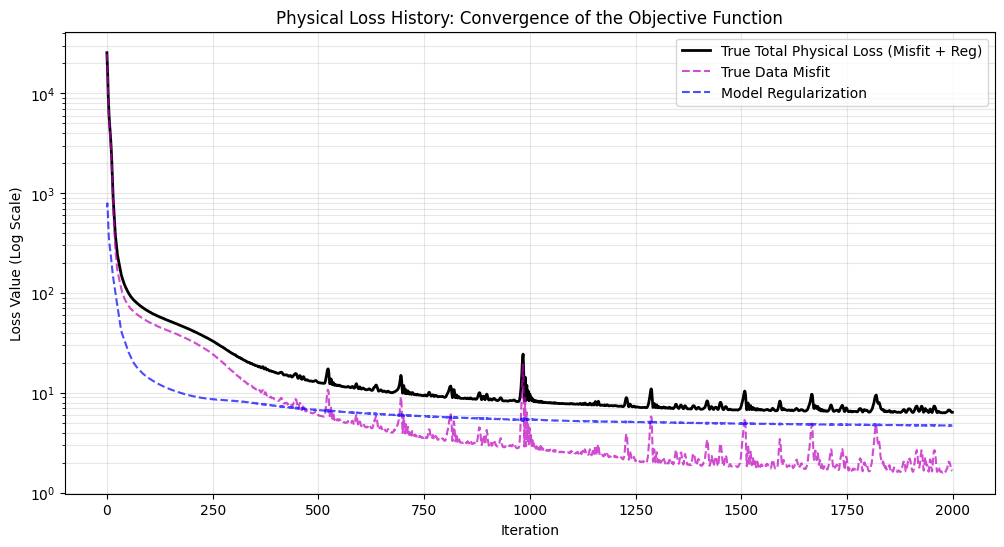

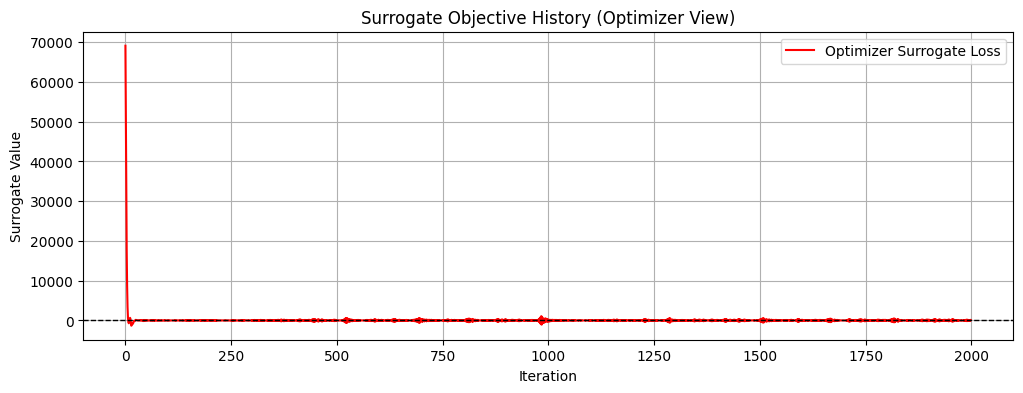

In [36]:
plt.figure(figsize=(12, 6))

# Plot the combined physical loss
plt.semilogy(np.array(true_total_loss_record), 'k-', linewidth=2, label='True Total Physical Loss (Misfit + Reg)')

# Plot individual components for detail
plt.semilogy(np.array(data_loss_record), 'm--', alpha=0.7, label='True Data Misfit')
plt.semilogy(np.array(model_reg_record), 'b--', alpha=0.7, label='Model Regularization')

plt.xlabel('Iteration')
plt.ylabel('Loss Value (Log Scale)')
plt.title('Physical Loss History: Convergence of the Objective Function')
plt.legend(loc='upper right')
plt.grid(True, which="both", ls="-", alpha=0.3)
plt.show()

# Second plot for the surrogate objective (the gradient-based proxy)
plt.figure(figsize=(12, 4))
plt.plot(np.array(surrogate_loss_record), 'r-', label='Optimizer Surrogate Loss')
plt.axhline(0, color='black', lw=1, ls='--') # Mark zero because surrogate can be negative
plt.xlabel('Iteration')
plt.ylabel('Surrogate Value')
plt.title('Surrogate Objective History (Optimizer View)')
plt.legend()
plt.grid(True)
plt.show()

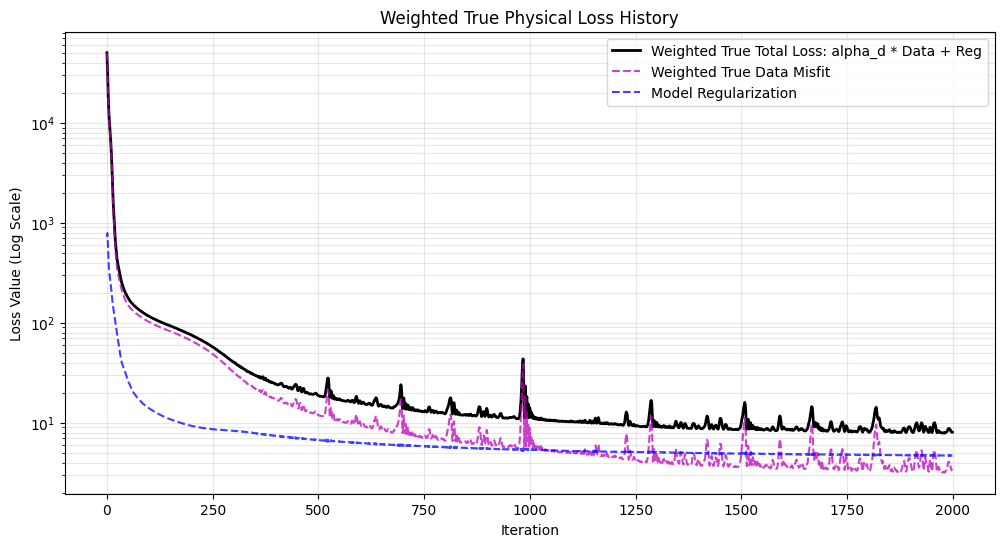

In [37]:
# Weighted true physical loss plot (consistent with alpha_d used in training)
true_weighted_total_loss_record = np.array(true_weighted_total_loss_record)

plt.figure(figsize=(12, 6))
plt.semilogy(true_weighted_total_loss_record, 'k-', linewidth=2, label='Weighted True Total Loss: alpha_d * Data + Reg')
plt.semilogy(alpha_d * np.array(data_loss_record), 'm--', alpha=0.75, label='Weighted True Data Misfit')
plt.semilogy(np.array(model_reg_record), 'b--', alpha=0.75, label='Model Regularization')
plt.xlabel('Iteration')
plt.ylabel('Loss Value (Log Scale)')
plt.title('Weighted True Physical Loss History')
plt.legend(loc='upper right')
plt.grid(True, which='both', ls='-', alpha=0.3)
plt.show()


In [38]:
tf.random.set_seed(42)
number_gaussian_realization = 500
codings_post_train = tf.random.normal(shape=[number_gaussian_realization, coding_size])

# Reshape d_sim to (1, data_dim) and cast to float32 before tiling
d_input_post_train = tf.cast(tf.reshape(d_sim, [1, data_dim]), dtype=tf.float32)
data_multiple_post_train = tf.tile(d_input_post_train, tf.constant([number_gaussian_realization, 1]))

# Use the trained decoder model for prediction
predicted_model_post_train_norm = decoder([codings_post_train, data_multiple_post_train])
predicted_model_post_train = susceptibility_scale * np.array(predicted_model_post_train_norm)

print("Shape of newly generated codings:", codings_post_train.shape)
print("Shape of tiled d_sim data:", data_multiple_post_train.shape)
print("Shape of normalized predicted model after training:", predicted_model_post_train_norm.shape)
print("Physical susceptibility range: min = {:.4e}, max = {:.4e}, mean = {:.4e}".format(
    np.min(predicted_model_post_train), np.max(predicted_model_post_train), np.mean(predicted_model_post_train)
))


Shape of newly generated codings: (500, 50)
Shape of tiled d_sim data: (500, 104)
Shape of normalized predicted model after training: (500, 3328)
Physical susceptibility range: min = 1.1922e-08, max = 4.7350e-02, mean = 1.6814e-02


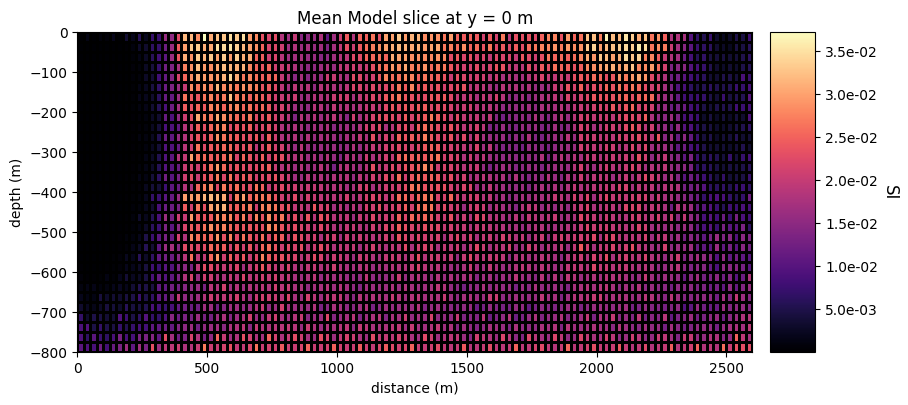

In [39]:
mean_model_post_train = np.mean(predicted_model_post_train, axis=0)

fig = plt.figure(figsize=(9, 4))

ax1 = fig.add_axes([0.08, 0.1, 0.75, 0.8])
mesh.plot_slice(
    plotting_map * mean_model_post_train,
    normal="Y",
    ax=ax1,
    ind=int(mesh.shape_cells[1] / 2),
    grid=True,
    clim=(np.min(mean_model_post_train), np.max(mean_model_post_train)),
    pcolor_opts={"cmap": "magma"},
)
ax1.set_title("Mean Model slice at y = 0 m")
ax1.set_xlabel('distance (m)')
ax1.set_ylabel('depth (m)')

ax2 = fig.add_axes([0.85, 0.1, 0.05, 0.8])
norm = matplotlib.colors.Normalize(vmin=np.min(mean_model_post_train), vmax=np.max(mean_model_post_train))
cbar = matplotlib.colorbar.ColorbarBase(
    ax2, norm=norm, orientation="vertical", cmap=matplotlib.cm.magma, format="%.1e"
)
cbar.set_label("SI", rotation=270, labelpad=15, size=12)

plt.show()

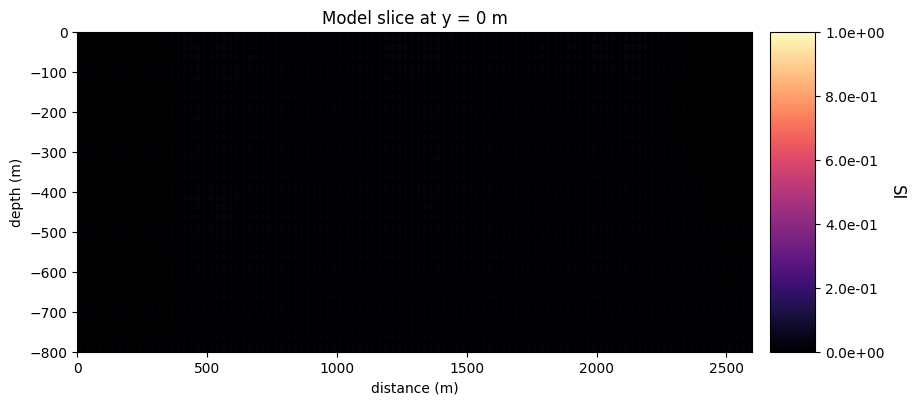

In [40]:
fig = plt.figure(figsize=(9, 4))

ax1 = fig.add_axes([0.08, 0.1, 0.75, 0.8])
mesh.plot_slice(
    plotting_map * np.squeeze(predicted_model_post_train[100,:]),
    normal="Y",
    ax=ax1,
    ind=int(mesh.shape_cells[1] / 2),
    grid=True,
    clim=(0,1),
    pcolor_opts={"cmap": "magma"},
)
ax1.set_title("Model slice at y = 0 m")
ax1.set_xlabel('distance (m)')
ax1.set_ylabel('depth (m)')

ax2 = fig.add_axes([0.85, 0.1, 0.05, 0.8])
norm = matplotlib.colors.Normalize(vmin=0, vmax=1)
cbar = matplotlib.colorbar.ColorbarBase(
    ax2, norm=norm, orientation="vertical", cmap=matplotlib.cm.magma, format="%.1e"
)
cbar.set_label("SI", rotation=270, labelpad=15, size=12)

plt.show()


In [41]:
std_model = np.std(np.array(predicted_model_post_train),axis=0)
std_model.shape

(3328,)

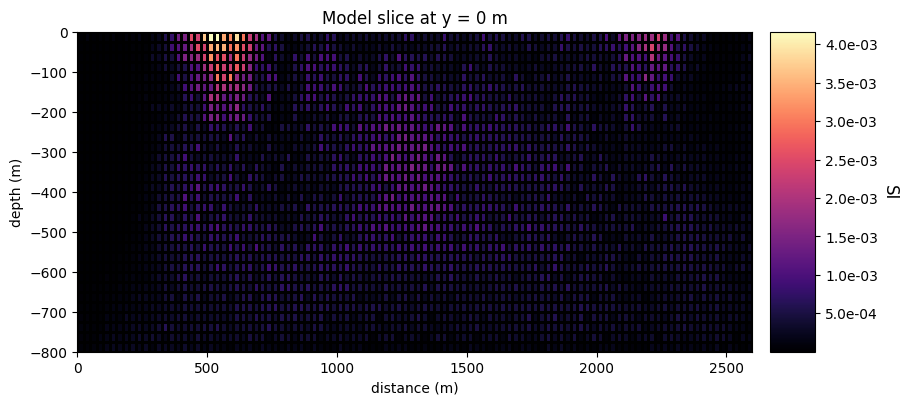

In [42]:
fig = plt.figure(figsize=(9, 4))

ax1 = fig.add_axes([0.08, 0.1, 0.75, 0.8])
mesh.plot_slice(
    plotting_map * std_model,
    normal="Y",
    ax=ax1,
    ind=int(mesh.shape_cells[1] / 2),
    grid=True,
    clim=(np.min(std_model),np.max(std_model)),
    pcolor_opts={"cmap": "magma"},
)
ax1.set_title("Model slice at y = 0 m")
ax1.set_xlabel('distance (m)')
ax1.set_ylabel('depth (m)')

ax2 = fig.add_axes([0.85, 0.1, 0.05, 0.8])
norm = matplotlib.colors.Normalize(vmin=np.min(std_model), vmax=np.max(std_model))
cbar = matplotlib.colorbar.ColorbarBase(
    ax2, norm=norm, orientation="vertical", cmap=matplotlib.cm.magma, format="%.1e"
)
cbar.set_label("SI", rotation=270, labelpad=15, size=12)

plt.show()

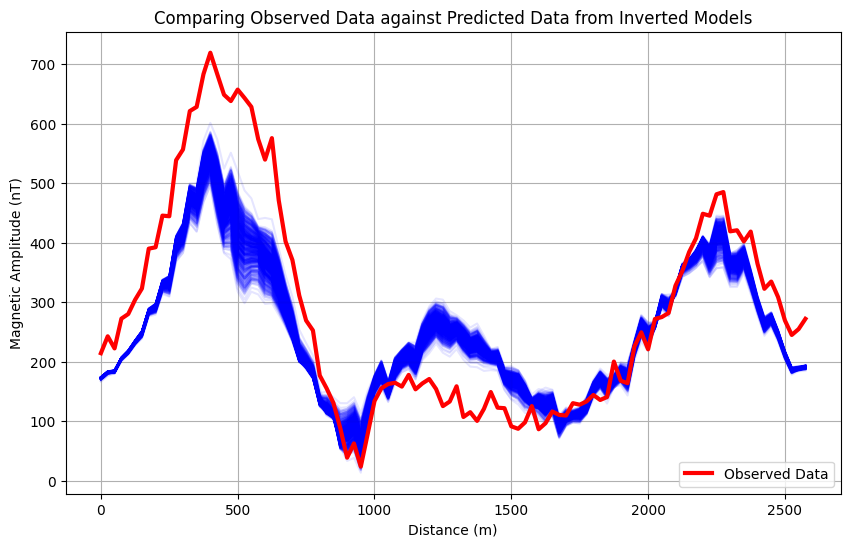

In [43]:
predicted_data = np.zeros([number_gaussian_realization, len(rxLoc)])

for i in range(number_gaussian_realization):
  predicted_data[i,:] = sim_wrapper.fields(np.squeeze(predicted_model_post_train[i,:]))

plt.figure(figsize=(10, 6))
# Plot all individual predicted data realizations with some transparency
for i in range(number_gaussian_realization):
  plt.plot(rxLoc[:,0], predicted_data[i,:], 'b-', alpha=0.1)

# Plot the observed (true) data
plt.plot(rxLoc[:,0], d_sim, 'r-', linewidth=3, label='Observed Data')

plt.title('Comparing Observed Data against Predicted Data from Inverted Models')
plt.xlabel('Distance (m)')
plt.ylabel('Magnetic Amplitude (nT)')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()
